In [1]:
%matplotlib inline

import os
import torch
import pandas as pd
import json
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torch.optim as optim



from torch import nn
from torch.utils.data import DataLoader, random_split, Dataset
from torchvision import datasets, transforms
from torchvision.transforms import v2
from functools import partial


torch.manual_seed(42)

# Switch to True if you want to retrain all models and keep False if it can use the earlier found results
FORCE_RETRAIN = False 

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device}")

Using cuda


# Task 1

## Data Loading

In [2]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

# Download training data from open datasets.
training_fashion = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

# Download test data from open datasets.
test_fashion = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform,
)

# Split 10% of the training data for validation
generator = torch.Generator().manual_seed(42)
train_fashion, val_fashion = random_split(training_fashion, [54000, 6000], generator=generator)


In [3]:
batch_size = 64

# Create data loaders.
train_dataloader = DataLoader(train_fashion, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_fashion, batch_size=batch_size)
val_dataloader = DataLoader(val_fashion, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


## Defining MLP and CNN classes

In [4]:
class MLP(nn.Module):
    def __init__(self, activation=nn.ReLU, width=512, dropout=0, depth=2, init=None, in_features= 28 * 28):
        super().__init__()
        self.flatten = nn.Flatten()

        layers = []
        for _ in range(depth):
            layers += [
                nn.Linear(in_features, width),
                activation(),
                nn.Dropout(dropout),
            ]
            in_features = width
        layers.append(nn.Linear(in_features, 10))

        self.layers = nn.Sequential(*layers)

        # Initialization
        if init is not None:
            for m in self.modules():
                if isinstance(m, nn.Linear):
                    init(m.weight)
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.flatten(x)
        return self.layers(x)

In [5]:
class CNN(nn.Module):
    def __init__(self, in_channels=1, image_size=28, activation=nn.ReLU, dropout=0.0, init = None, channels=(6, 16), kernel_size=5):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, channels[0], kernel_size)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(channels[0], channels[1], kernel_size)

        # Fully connected layers
        size = ((image_size - kernel_size + 1) // 2 - kernel_size + 1) // 2
        self.fc1 = nn.Linear(channels[1] * size * size, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

        self.act = activation()
        self.dropout = nn.Dropout(dropout)

        # Initialization
        if init is not None:
            for m in self.modules():
                if isinstance(m, (nn.Linear, nn.Conv2d)):
                    init(m.weight)
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.pool(self.act(self.conv1(x)))
        x = self.pool(self.act(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = self.dropout(self.act(self.fc1(x)))
        x = self.dropout(self.act(self.fc2(x)))
        x = self.fc3(x)
        return x

## Training and Evaluation Functions

In [6]:
def train_epoch(model, dataloader, loss_fn, optimizer):
    model.train()
    total_loss = 0
    size = len(dataloader.dataset)
    num_batches = len(dataloader)


    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        total_loss += loss.item()

        # Updates during process by giving loss every 100th batch
        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

    return total_loss / num_batches

def evaluate(model, dataloader, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    avg_loss = test_loss / num_batches
    accuracy  = correct / size

    return avg_loss, accuracy

## Creating baselines for MLP and CNN

In [7]:
learning_rate = 1e-3
batch_size = 64
epochs = 15

mlp_baseline_path = "results/mlp_baseline_history.json"

if os.path.exists(mlp_baseline_path) and not FORCE_RETRAIN:
    with open(mlp_baseline_path) as f:
        mlp_baseline_history = json.load(f)
    print(f"Loaded mlp_baseline_history from {mlp_baseline_path}")

else: 
    torch.manual_seed(42)

    model = MLP().to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    mlp_baseline_history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        train_loss = train_epoch(model, train_dataloader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_dataloader, loss_fn)

        mlp_baseline_history["train_loss"].append(train_loss)
        mlp_baseline_history["val_loss"].append(val_loss)
        mlp_baseline_history["val_acc"].append(val_acc)
        
        print(f"epoch {epoch+1}: train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")

    with open("results/mlp_baseline_history.json", "w") as f:
        json.dump(mlp_baseline_history, f, indent=1)

Loaded mlp_baseline_history from results/mlp_baseline_history.json


In [8]:
cnn_baseline_path = "results/cnn_baseline_history.json"

if os.path.exists(cnn_baseline_path) and not FORCE_RETRAIN:
    with open(cnn_baseline_path) as f:
        cnn_baseline_history = json.load(f)
    print(f"Loaded cnn_baseline_history from {cnn_baseline_path}")

else: 
    torch.manual_seed(42)

    model = CNN().to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    cnn_baseline_history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        train_loss = train_epoch(model, train_dataloader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_dataloader, loss_fn)

        cnn_baseline_history["train_loss"].append(train_loss)
        cnn_baseline_history["val_loss"].append(val_loss)
        cnn_baseline_history["val_acc"].append(val_acc)

        print(f"epoch {epoch+1}: train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")


    with open("results/cnn_baseline_history.json", "w") as f:
        json.dump(cnn_baseline_history, f, indent=1)

Loaded cnn_baseline_history from results/cnn_baseline_history.json


## Hyperparameter experiments on Fashion-MNIST dataset 

In [9]:
# All hyperparameters we are going to experiment with
activations = {
    "relu": nn.ReLU,
    "leaky_relu": partial(nn.LeakyReLU, 0.01),
    "gelu": nn.GELU,
    "tanh": nn.Tanh,
}
inits = {
    "default": None,                                    # PyTorch's built-in init
    "kaiming": nn.init.kaiming_normal_,
    "xavier": nn.init.xavier_uniform_,
    "normal": partial(nn.init.normal_, mean=0.0, std=0.01),
}
optimizers = {
    "sgd": partial(optim.SGD, momentum=0.9),
    "adam": optim.Adam,                                 # weight_decay here = L2 penalty
    "adamw": optim.AdamW,                               # weight_decay here = decoupled decay
}

# Base Configuration 
base = dict(
    init="default", activation="relu",
    optimizer="adam", lr=1e-3,
    dropout=0.0, weight_decay=0.0,
    depth=2, width=512,
    epochs=15, patience=3,
)

In [10]:
# Trains a model with early stopping and saves the results of the run
def run_epochs_with_patience_save_results(model, train_dataloader, val_dataloader, loss_fn, optimizer, results, cfg, name):    
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    bad_epochs = 0

    for epoch in range(cfg["epochs"]):
        train_loss = train_epoch(model, train_dataloader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_dataloader, loss_fn)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            bad_epochs = 0

        else:
            bad_epochs += 1
            if bad_epochs >= cfg["patience"]:
                print(f"Early stopping - epoch {epoch}")
                break

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"epoch {epoch+1}: train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")

    best_epoch = history["val_loss"].index(best_val_loss)
    
    results.append({
        "name": name, **cfg,
        "config":cfg,
        "best_val_loss": best_val_loss,
        "best_val_acc": history["val_acc"][best_epoch],
        "best_epoch": best_epoch + 1,
        "params": sum(p.numel() for p in model.parameters()),
        "history": history,
    })

In [11]:
def train_MLP(cfg, train_dataloader, val_dataloader, results, in_features, name):
    
    print(f'training MLP with config {cfg}')

    torch.manual_seed(42)
    loss_fn = nn.CrossEntropyLoss()

    model = MLP(activation=activations[cfg["activation"]], 
                width=cfg["width"], 
                dropout=cfg["dropout"], 
                depth=cfg["depth"],
                init=inits[cfg["init"]],
                in_features=in_features
                ).to(device)

    optimizer = optimizers[cfg["optimizer"]](
        model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )

    run_epochs_with_patience_save_results(model, train_dataloader, val_dataloader, loss_fn, optimizer, results, cfg, name)

In [12]:
def train_CNN(cfg, train_dataloader, val_dataloader, results, name, in_channels=1, image_size=28):
    
    print(f'training CNN with config {cfg}')

    torch.manual_seed(42)
    loss_fn = nn.CrossEntropyLoss()

    model = CNN(in_channels=in_channels,           
                image_size=image_size,              
                channels=cfg["channels"],           
                kernel_size=cfg["kernel_size"],     
                activation=activations[cfg["activation"]], 
                dropout=cfg["dropout"], 
                init=inits[cfg["init"]],
                ).to(device)

    optimizer = optimizers[cfg["optimizer"]](
        model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )

    run_epochs_with_patience_save_results(model, train_dataloader, val_dataloader, loss_fn, optimizer, results, cfg, name)

In [13]:
# Each entry changes only what differs from the baseline (one factor at a time) for MLP
variations_mlp = [
    {},                                                 # baseline
    # parameter initialization
    {"init": "kaiming"}, {"init": "xavier"}, {"init": "normal"},
    # activation functions
    {"activation": "leaky_relu"}, {"activation": "gelu"}, {"activation": "tanh"},
    # optimizers + learning rates (paired, since good lr depends on the optimizer)
    {"optimizer": "sgd", "lr": 0.1}, {"optimizer": "sgd", "lr": 0.01},
    {"optimizer": "adam", "lr": 1e-4},
    {"optimizer": "adamw", "lr": 1e-3}, {"optimizer": "adamw", "lr": 1e-4},
    # regularization
    {"dropout": 0.2}, {"dropout": 0.5},
    {"weight_decay": 1e-4},                             # L2 penalty via Adam
    {"optimizer": "adamw", "weight_decay": 1e-2},       # decoupled weight decay
    {"dropout": 0.2, "optimizer": "adamw", "weight_decay": 1e-2},
    # architecture
    {"depth": 1}, {"depth": 4},
    {"width": 128}, {"width": 1024},
]

configs_mlp = [base | v for v in variations_mlp]

mlp_sweep_path = "results/mlp_sweep.json"

if os.path.exists(mlp_sweep_path) and not FORCE_RETRAIN:
    with open(mlp_sweep_path) as f:
        results_mlp = json.load(f)
    print(f"Loaded results from {mlp_sweep_path}")

else: 
    results_mlp = []

    for i, (cfg, change) in enumerate(zip(configs_mlp, variations_mlp), 1):
        name = ", ".join(f"{k}={v}" for k, v in change.items()) or "baseline"
        print(f"\n=== {i}/{len(configs_mlp)}: {name} ===")

        train_MLP(cfg=cfg,
                    train_dataloader=train_dataloader,
                    val_dataloader=val_dataloader,
                    results=results_mlp,
                    in_features=28 * 28,
                    name=name)

df_mlp = pd.DataFrame(results_mlp).drop(columns="history").sort_values("best_val_loss")

# Save results: CSV for reading/report, JSON incl. per-epoch history for plots
os.makedirs("results", exist_ok=True)
df_mlp.to_csv("results/mlp_sweep.csv", index=False)
with open("results/mlp_sweep.json", "w") as f:
    json.dump(results_mlp, f, indent=1)

df_mlp



Loaded results from results/mlp_sweep.json


,name,init,activation,optimizer,lr,dropout,weight_decay,depth,width,epochs,patience,config,best_val_loss,best_val_acc,best_epoch,params
8,"optimizer=sgd, lr=0.01",default,relu,sgd,0.0100,0.0,0.0000,2,512,15,3,"{'init': 'default', 'activation': 'relu', 'opt...",0.289119,0.894333,15,669706
5,activation=gelu,default,gelu,adam,0.0010,0.0,0.0000,2,512,15,3,"{'init': 'default', 'activation': 'gelu', 'opt...",0.294943,0.892833,7,669706
2,init=xavier,xavier,relu,adam,0.0010,0.0,0.0000,2,512,15,3,"{'init': 'xavier', 'activation': 'relu', 'opti...",0.300400,0.893333,9,669706
3,init=normal,normal,relu,adam,0.0010,0.0,0.0000,2,512,15,3,"{'init': 'normal', 'activation': 'relu', 'opti...",0.300835,0.893333,9,669706
1,init=kaiming,kaiming,relu,adam,0.0010,0.0,0.0000,2,512,15,3,"{'init': 'kaiming', 'activation': 'relu', 'opt...",0.301111,0.888833,7,669706
16,"dropout=0.2, optimizer=adamw, weight_decay=0.01",default,relu,adamw,0.0010,0.2,0.0100,2,512,15,3,"{'init': 'default', 'activation': 'relu', 'opt...",0.301773,0.889500,12,669706
9,"optimizer=adam, lr=0.0001",default,relu,adam,0.0001,0.0,0.0000,2,512,15,3,"{'init': 'default', 'activation': 'relu', 'opt...",0.303275,0.886833,15,669706
11,"optimizer=adamw, lr=0.0001",default,relu,adamw,0.0001,0.0,0.0000,2,512,15,3,"{'init': 'default', 'activation': 'relu', 'opt...",0.303275,0.886833,15,669706
17,depth=1,default,relu,adam,0.0010,0.0,0.0000,1,512,15,3,"{'init': 'default', 'activation': 'relu', 'opt...",0.306376,0.887500,8,407050
12,dropout=0.2,default,relu,adam,0.0010,0.2,0.0000,2,512,15,3,"{'init': 'default', 'activation': 'relu', 'opt...",0.309021,0.882667,7,669706


In [14]:
base_cnn = {k: v for k, v in base.items() if k not in ("depth", "width")} | dict(
    channels=(6, 16), kernel_size=5,
)

# Each entry changes only what differs from the baseline (one factor at a time) for CNN
variations_cnn = [
    {},                                                 # baseline
    # parameter initialization
    {"init": "kaiming"}, {"init": "xavier"}, {"init": "normal"},
    # activation functions
    {"activation": "leaky_relu"}, {"activation": "gelu"}, {"activation": "tanh"},
    # optimizers + learning rates (paired, since good lr depends on the optimizer)
    {"optimizer": "sgd", "lr": 0.1}, {"optimizer": "sgd", "lr": 0.01},
    {"optimizer": "adam", "lr": 1e-4},
    {"optimizer": "adamw", "lr": 1e-3}, {"optimizer": "adamw", "lr": 1e-4},
    # regularization
    {"dropout": 0.2}, {"dropout": 0.5},
    {"weight_decay": 1e-4},                             # L2 penalty via Adam
    {"optimizer": "adamw", "weight_decay": 1e-2},       # decoupled weight decay
    {"dropout": 0.2, "optimizer": "adamw", "weight_decay": 1e-2},
    # architecture: number of filters (kernel size fixed at 5)
    {"channels": (3, 8)},  {"channels": (16, 32)},  {"channels": (32, 64)},
    # architecture: kernel size (filters fixed at 6/16)
    {"kernel_size": 3},    {"kernel_size": 7},
]
configs_cnn = [base_cnn | v for v in variations_cnn]

cnn_sweep_path = "results/cnn_sweep.json"

if os.path.exists(cnn_sweep_path) and not FORCE_RETRAIN:
    with open(cnn_sweep_path) as f:
        results_cnn = json.load(f)
    print(f"Loaded results from {cnn_sweep_path}")

else: 
    results_cnn = []

    for i, (cfg, change) in enumerate(zip(configs_cnn, variations_cnn), 1):
        name = ", ".join(f"{k}={v}" for k, v in change.items()) or "baseline"
        print(f"\n=== {i}/{len(configs_cnn)}: {name} ===")

        train_CNN(cfg=cfg,
                    train_dataloader=train_dataloader,
                    val_dataloader=val_dataloader,
                    results=results_cnn,
                    name=name)

df_cnn = pd.DataFrame(results_cnn).drop(columns="history").sort_values("best_val_loss")

# Save results: CSV for reading/report, JSON incl. per-epoch history for plots
os.makedirs("results", exist_ok=True)
df_cnn.to_csv("results/cnn_sweep.csv", index=False)
with open("results/cnn_sweep.json", "w") as f:
    json.dump(results_cnn, f, indent=1)

df_cnn

Loaded results from results/cnn_sweep.json


,name,init,activation,optimizer,lr,dropout,weight_decay,epochs,patience,channels,kernel_size,config,best_val_loss,best_val_acc,best_epoch,params
19,"channels=(32, 64)",default,relu,adam,0.0010,0.0,0.0000,15,3,"[32, 64]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.233030,0.918333,7,186110
18,"channels=(16, 32)",default,relu,adam,0.0010,0.0,0.0000,15,3,"[16, 32]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.254839,0.908667,11,85822
2,init=xavier,xavier,relu,adam,0.0010,0.0,0.0000,15,3,"[6, 16]",5,"{'init': 'xavier', 'activation': 'relu', 'opti...",0.268250,0.904167,13,44426
0,baseline,default,relu,adam,0.0010,0.0,0.0000,15,3,"[6, 16]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.276674,0.900333,15,44426
15,"optimizer=adamw, weight_decay=0.01",default,relu,adamw,0.0010,0.0,0.0100,15,3,"[6, 16]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.277323,0.899167,15,44426
10,"optimizer=adamw, lr=0.001",default,relu,adamw,0.0010,0.0,0.0000,15,3,"[6, 16]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.279564,0.896833,13,44426
12,dropout=0.2,default,relu,adam,0.0010,0.2,0.0000,15,3,"[6, 16]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.279730,0.900667,15,44426
14,weight_decay=0.0001,default,relu,adam,0.0010,0.0,0.0001,15,3,"[6, 16]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.280322,0.899833,11,44426
4,activation=leaky_relu,default,leaky_relu,adam,0.0010,0.0,0.0000,15,3,"[6, 16]",5,"{'init': 'default', 'activation': 'leaky_relu'...",0.283246,0.899500,11,44426
16,"dropout=0.2, optimizer=adamw, weight_decay=0.01",default,relu,adamw,0.0010,0.2,0.0100,15,3,"[6, 16]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.283556,0.895667,14,44426


## Using top 3 configurations for CIFAR-10

In [15]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

# Download training data from open datasets.
training_cifar = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

# Download test data from open datasets.
test_cifar = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transform,
)

# Split 10% of the training data for validation
generator = torch.Generator().manual_seed(42)
train_cifar, val_cifar = random_split(training_cifar, [45000, 5000], generator=generator)

Files already downloaded and verified
Files already downloaded and verified


In [16]:
# Create dataloaders and finds top 3 configurations
batch_size = 64

train_cifar_dataloader = DataLoader(train_cifar, batch_size=batch_size, shuffle=True)
test_cifar_dataloader = DataLoader(test_cifar, batch_size=batch_size)
val_cifar_dataloader = DataLoader(val_cifar, batch_size=batch_size)

# Opens results from the sweeps and finds top 3 configurations for MLP and CNN 
with open("results/mlp_sweep.json") as f:
    mlp_loaded = json.load(f)

with open("results/cnn_sweep.json") as f:
    cnn_loaded = json.load(f)

sorted_loss_mlp = sorted(mlp_loaded, key=lambda s: s["best_val_loss"]) 
top_3_mlp = sorted_loss_mlp[:3]

sorted_loss_cnn = sorted(cnn_loaded, key=lambda s: s["best_val_loss"]) 
top_3_cnn = sorted_loss_cnn[:3]

In [17]:
# MLP on CIFAR dataset with top 3 config
mlp_cifar_path = "results/cifar_mlp.json"
cnn_cifar_path = "results/cifar_cnn.json"

if os.path.exists(mlp_cifar_path) and os.path.exists(cnn_cifar_path) and not FORCE_RETRAIN:
    with open(mlp_cifar_path) as f:
        results_cifar_mlp = json.load(f)
    print(f"Loaded results_cifar_mlp from {mlp_cifar_path}")

    with open(cnn_cifar_path) as f:
        results_cifar_cnn = json.load(f)
    print(f"Loaded results_cifar_cnn from {cnn_cifar_path}")


else: 
    results_cifar_mlp = []
    for configuration in top_3_mlp:
        train_MLP(cfg=configuration["config"], 
                train_dataloader=train_cifar_dataloader, 
                val_dataloader=val_cifar_dataloader, 
                results=results_cifar_mlp, 
                in_features= 32 * 32 * 3, 
                name=f"CIFAR - {configuration['name']}")

    # CNN on CIFAR dataset with top 3 config
    results_cifar_cnn = []
    for configuration in top_3_cnn:
        train_CNN(cfg=configuration["config"], 
                train_dataloader=train_cifar_dataloader, 
                val_dataloader=val_cifar_dataloader, 
                results=results_cifar_cnn, 
                in_channels=3, 
                image_size=32,
                name=f"CIFAR - {configuration['name']}")


# Save results and show corresponding tables
os.makedirs("results", exist_ok=True)

df_cifar_mlp = pd.DataFrame(results_cifar_mlp).drop(columns="history").sort_values("best_val_loss")
df_cifar_cnn = pd.DataFrame(results_cifar_cnn).drop(columns="history").sort_values("best_val_loss")

df_cifar_mlp.to_csv("results/cifar_mlp.csv", index=False)
df_cifar_cnn.to_csv("results/cifar_cnn.csv", index=False)

with open("results/cifar_mlp.json", "w") as f:
    json.dump(results_cifar_mlp, f, indent=1)

with open("results/cifar_cnn.json", "w") as f:
    json.dump(results_cifar_cnn, f, indent=1)

display(df_cifar_mlp)
display(df_cifar_cnn)

Loaded results_cifar_mlp from results/cifar_mlp.json
Loaded results_cifar_cnn from results/cifar_cnn.json


,name,init,activation,optimizer,lr,dropout,weight_decay,depth,width,epochs,patience,config,best_val_loss,best_val_acc,best_epoch,params
0,"CIFAR - optimizer=sgd, lr=0.01",default,relu,sgd,0.010,0.0,0.0,2,512,15,3,"{'init': 'default', 'activation': 'relu', 'opt...",1.368423,0.5204,13,1841162
1,CIFAR - activation=gelu,default,gelu,adam,0.001,0.0,0.0,2,512,15,3,"{'init': 'default', 'activation': 'gelu', 'opt...",1.424590,0.4918,10,1841162
2,CIFAR - init=xavier,xavier,relu,adam,0.001,0.0,0.0,2,512,15,3,"{'init': 'xavier', 'activation': 'relu', 'opti...",1.479687,0.4718,7,1841162


,name,init,activation,optimizer,lr,dropout,weight_decay,epochs,patience,channels,kernel_size,config,best_val_loss,best_val_acc,best_epoch,params
0,"CIFAR - channels=(32, 64)",default,relu,adam,0.001,0.0,0.0,15,3,"[32, 64]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.937709,0.6752,9,256830
1,"CIFAR - channels=(16, 32)",default,relu,adam,0.001,0.0,0.0,15,3,"[16, 32]",5,"{'init': 'default', 'activation': 'relu', 'opt...",0.977896,0.6574,10,121182
2,CIFAR - init=xavier,xavier,relu,adam,0.001,0.0,0.0,15,3,"[6, 16]",5,"{'init': 'xavier', 'activation': 'relu', 'opti...",1.109886,0.6100,8,62006


## Making plots for task 1

In [18]:
# Baseline comparison between MLP and CNN
def plot_history(history, title="Baseline"):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    ax1.plot(epochs, history["train_loss"], label="train")
    ax1.plot(epochs, history["val_loss"], label="validation")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("cross-entropy loss")
    ax1.set_title("Loss")
    ax1.legend()

    ax2.plot(epochs, history["val_acc"], label="validation", color="tab:orange")
    ax2.set_xlabel("epoch")
    ax2.set_ylabel("accuracy")
    ax2.set_title("Validation accuracy")
    ax2.legend()

    fig.suptitle(title)
    fig.tight_layout()
    
    os.makedirs("figures", exist_ok=True)
    plt.savefig(f"figures/{title}.png", dpi=150, bbox_inches="tight")

    plt.show()


def plot_comparison(results, metric="val_loss", title=None):
    """One curve per experiment, for a single metric."""
    plt.figure(figsize=(7, 4))
    for name, history in results.items():
        epochs = range(1, len(history[metric]) + 1)
        plt.plot(epochs, history[metric], label=name)
    plt.xlabel("epoch")
    plt.ylabel(metric)
    plt.title(title or metric)
    plt.legend()
    plt.tight_layout()
    
    os.makedirs("figures", exist_ok=True)
    plt.savefig(f"figures/{title}.png", dpi=150, bbox_inches="tight")

    plt.show()

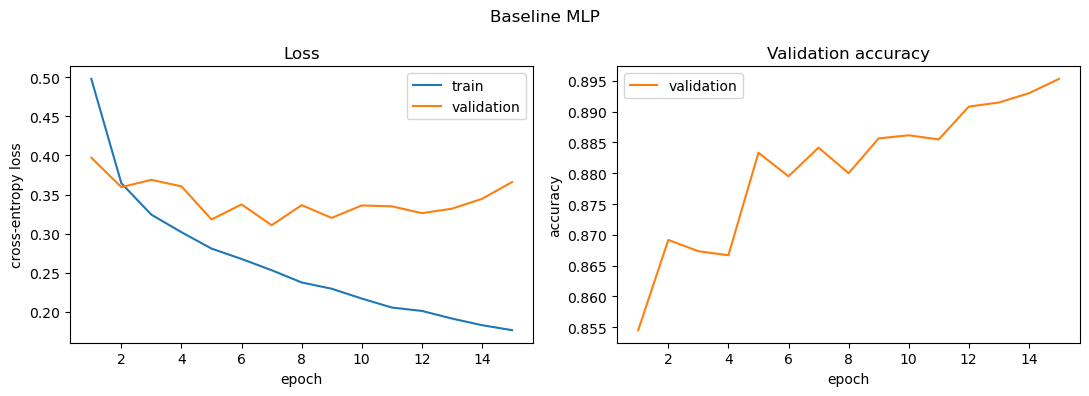

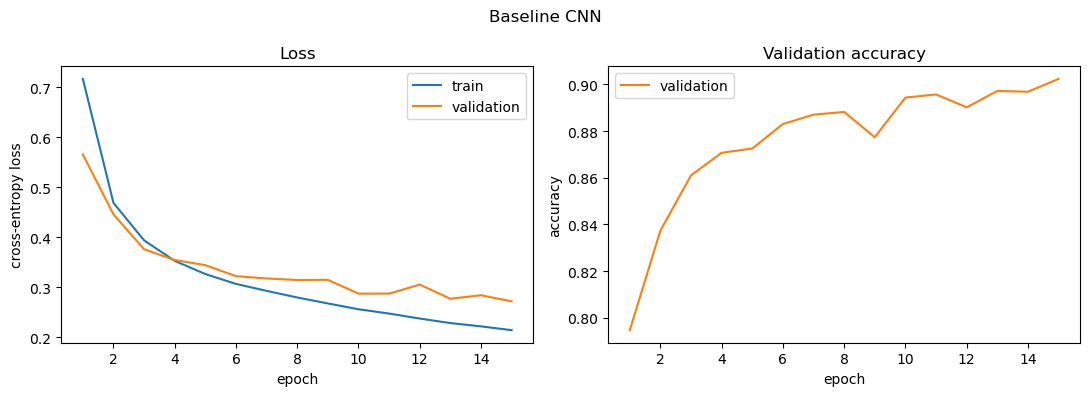

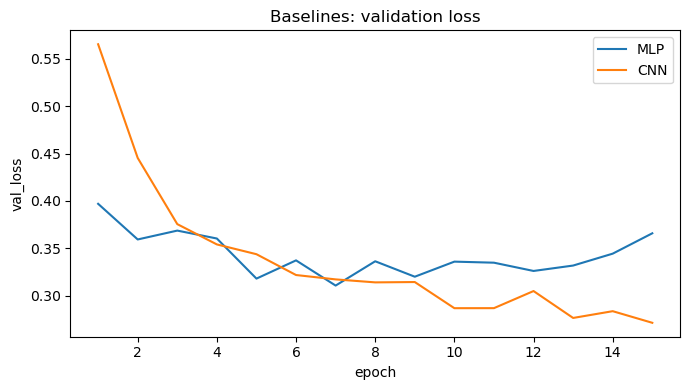

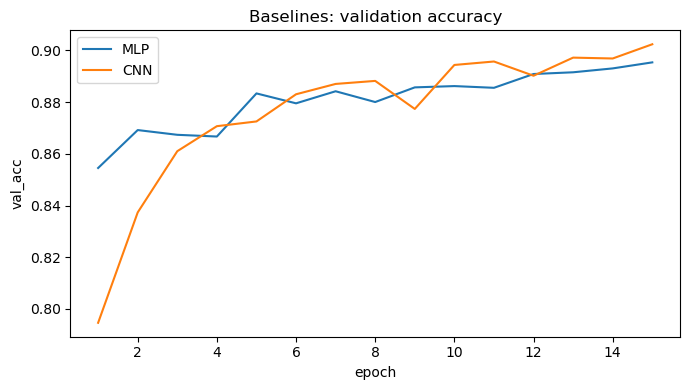

In [19]:
plot_history(mlp_baseline_history, title="Baseline MLP")
plot_history(cnn_baseline_history, title="Baseline CNN")

# MLP vs CNN baseline
baselines = {"MLP": mlp_baseline_history, "CNN": cnn_baseline_history}
plot_comparison(baselines, metric="val_loss", title="Baselines: validation loss")
plot_comparison(baselines, metric="val_acc", title="Baselines: validation accuracy")


# Task 2

In [ ]:
# Create CustomDataset such that we can apply randomsplits 
class CustomDataset(Dataset):
    def __init__(self, x, y, dtype_y, transform):
      self.x = x
      self.y = y
      self.dtype_y = dtype_y
      self.transform = transform

    def __getitem__(self, index):
      added_channel = np.expand_dims(self.x, axis=-1)  # Add color channel to the end such that it has the expexted np shape
      transformed_x = self.transform(added_channel[index])
      return (transformed_x, torch.tensor(self.y[index], dtype=self.dtype_y))

    def __len__(self):
        return len(self.x)


""" 
Problems with using high cardinality classification:
- Each bin is independent of eachother. Meaning that times that are 1 minute apart have no connection and close guesses don't play a role in the cross entropy loss
- Some classes might have very few or no training examples
- 
"""

class CNN_classification(nn.Module):
    def __init__(self, in_channels=1, image_size=75, activation=nn.ReLU, dropout=0.0, num_classes=720):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)

        # Fully connected layers
        size = ((image_size - 4) // 2 - 4) // 2
        self.fc1 = nn.Linear(16 * size * size, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)  # Basically the only change compared to the baseline

        self.act = activation()
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        x = self.pool(self.act(self.conv1(x)))
        x = self.pool(self.act(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = self.dropout(self.act(self.fc1(x)))
        x = self.dropout(self.act(self.fc2(x)))
        x = self.fc3(x)
        return x


In [ ]:
def classification_labels(y, num_classes=720):
    y_minutes = y[:,0]*60 + y[:,1]
    total_minutes = 60*12

    # create bin edges
    bin_edges = np.linspace(0, total_minutes, num_classes+1)
    # bin the data
    bin_indices = np.digitize(y_minutes, bin_edges) - 1

    return bin_indices


def common_sense_error_classification(y_pred, y_real, num_classes):
    # We take the bincenters as distance measure unless there is a prediction label for each minute
    if num_classes != 720:
        size_interval = 720 / num_classes
        pred_bin_center = y_pred * size_interval + 0.5 * size_interval

        diff = torch.remainder(torch.abs(y_real-pred_bin_center), 720)  # If difference is bigger than full clock cycle take the remainder
        cse = torch.minimum(diff, 720-diff)

    else:
        diff = torch.remainder(torch.abs(y_real-y_pred), 720)
        cse = torch.minimum(diff, 720-diff)
    return torch.mean(cse)

def test_error_classification(model, num_classes, dataloader, per_minute_dataloader=test_dataloader_1min_75, error_fn = common_sense_error_classification):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_error, correct = 0, 0

    with torch.no_grad():
        for X, y in per_minute_dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_error += error_fn(pred.argmax(1), y, num_classes).item() * len(y)

        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    avg_error = test_error / size
    accuracy  = correct / size

    return avg_error, accuracy

In [ ]:
# Download the datasets and open them here
clock_75_images = np.load("data/Clock/images_75.npy")
clock_75_labels = np.load("data/Clock/labels_75.npy")

clock_150_images = np.load("data/Clock/images_150.npy")
clock_150_labels = np.load("data/Clock/labels_150.npy")

In [ ]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

cls_dataset_30min_75 = CustomDataset(x=clock_75_images, y=classification_labels(clock_75_labels, num_classes=24), dtype_y=torch.long, transform=transform)
cls_dataset_15min_75 = CustomDataset(x=clock_75_images, y=classification_labels(clock_75_labels, num_classes=48), dtype_y=torch.long, transform=transform)
cls_dataset_5min_75 = CustomDataset(x=clock_75_images, y=classification_labels(clock_75_labels, num_classes=144), dtype_y=torch.long, transform=transform)
cls_dataset_1min_75 = CustomDataset(x=clock_75_images, y=classification_labels(clock_75_labels, num_classes=720), dtype_y=torch.long, transform=transform)

len_dataset = len(clock_75_images)
# Split 10% of the training data for validation and 10% for testing
generator = torch.Generator().manual_seed(42)
train_30min_75, val_30min_75, test_30min_75 = random_split(cls_dataset_30min_75, [int(0.8*len_dataset), int(0.1*len_dataset), int(0.1*len_dataset)], generator=generator)

generator = torch.Generator().manual_seed(42)
train_15min_75, val_15min_75, test_15min_75 = random_split(cls_dataset_15min_75, [int(0.8*len_dataset), int(0.1*len_dataset), int(0.1*len_dataset)], generator=generator)

generator = torch.Generator().manual_seed(42)
train_5min_75, val_5min_75, test_5min_75 = random_split(cls_dataset_5min_75, [int(0.8*len_dataset), int(0.1*len_dataset), int(0.1*len_dataset)], generator=generator)

generator = torch.Generator().manual_seed(42)
train_1min_75, val_1min_75, test_1min_75 = random_split(cls_dataset_1min_75, [int(0.8*len_dataset), int(0.1*len_dataset), int(0.1*len_dataset)], generator=generator)
"""
Important do not remove the generator before each random_split. This ensures that we split the dataset on the same indices each time which is needed for the common sense error
"""
print(test_30min_75.indices == test_1min_75.indices)
print(test_15min_75.indices == test_1min_75.indices)
print(test_5min_75.indices == test_1min_75.indices)

In [ ]:
batch_size = 64

# Create data loaders
train_dataloader_30min_75 = DataLoader(train_30min_75, batch_size=batch_size, shuffle=True)
test_dataloader_30min_75 = DataLoader(test_30min_75, batch_size=batch_size)
val_dataloader_30min_75 = DataLoader(val_30min_75, batch_size=batch_size)

train_dataloader_15min_75 = DataLoader(train_15min_75, batch_size=batch_size, shuffle=True)
test_dataloader_15min_75 = DataLoader(test_15min_75, batch_size=batch_size)
val_dataloader_15min_75 = DataLoader(val_15min_75, batch_size=batch_size)

train_dataloader_5min_75 = DataLoader(train_5min_75, batch_size=batch_size, shuffle=True)
test_dataloader_5min_75 = DataLoader(test_5min_75, batch_size=batch_size)
val_dataloader_5min_75 = DataLoader(val_5min_75, batch_size=batch_size)

train_dataloader_1min_75 = DataLoader(train_1min_75, batch_size=batch_size, shuffle=True)
test_dataloader_1min_75 = DataLoader(test_1min_75, batch_size=batch_size)
val_dataloader_1min_75 = DataLoader(val_1min_75, batch_size=batch_size)

for X, y in test_dataloader_30min_75:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

In [ ]:
learning_rate = 1e-3
batch_size = 64
epochs = 15

torch.manual_seed(42)
model_30min_75 = CNN_classification(in_channels=1, image_size=75, activation=nn.ReLU, dropout=0.0, num_classes=24).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer_30min_75 = torch.optim.Adam(model_30min_75.parameters(), lr=learning_rate)

history = {"train_loss_30min_75": [], "val_loss_30min_75": [], "val_acc_30min_75": []}
for epoch in range(epochs):
    train_loss = train_epoch(model_30min_75, train_dataloader_30min_75, loss_fn, optimizer_30min_75)
    val_loss, val_acc = evaluate(model_30min_75, val_dataloader_30min_75, loss_fn)
    history["train_loss_30min_75"].append(train_loss)
    history["val_loss_30min_75"].append(val_loss)
    history["val_acc_30min_75"].append(val_acc)
    print(f"epoch {epoch+1}: train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")

torch.save(model_30min_75.state_dict(), 'models/model_imsize_75_numc_24.pth')

In [ ]:
model = CNN_classification(num_classes=24).to(device)
model.load_state_dict(torch.load("models/model_imsize_75_numc_24.pth", weights_only=True))
avg_error_30min_75, accuracy_30min_75 = test_error_classification(model, 24, test_dataloader_30min_75)
print(f"Classification CNN 30 min bins: Average Test Error {avg_error_30min_75:.1f} minutes | Accuracy {accuracy_30min_75:.3f}")

### Regression

In [ ]:
class CNN_Regression(nn.Module):
    def __init__(self, in_channels=1, image_size=75, activation=nn.ReLU, dropout=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)

        # Fully connected layers
        size = ((image_size - 4) // 2 - 4) // 2
        self.fc1 = nn.Linear(16 * size * size, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 1)

        self.act = activation()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.pool(self.act(self.conv1(x)))
        x = self.pool(self.act(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = self.dropout(self.act(self.fc1(x)))
        x = self.dropout(self.act(self.fc2(x)))
        x = self.fc3(x)
        return x


class CustomLoss(nn.Module):
    def __init__(self):
        super(CustomLoss, self).__init__()
    def forward(self, predictions, targets):
        diff = torch.remainder(torch.abs(predictions-targets), 12)  # If difference is bigger than full clock cycle take the remainder
        cse = torch.minimum(diff, 12 - diff)
        mse_loss = torch.mean(cse ** 2)
        return mse_loss 

In [ ]:
def regression_labels(y):
   y_scalar = y[:,0] + y[:,1]/60
   return y_scalar

def common_sense_error_regression(y_pred, y_real):
    diff = torch.remainder(torch.abs(y_pred-y_real), 12)  # If difference is bigger than full clock cycle take the remainder
    cse = torch.minimum(diff, 12 - diff)
    return torch.mean(cse)

def test_error_regression(model, dataloader, error_fn = common_sense_error_regression):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_error = 0

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_error += error_fn(pred.argmax(1), y).item() * len(y)

    avg_error = test_error / size

    return avg_error


In [ ]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
dataset_reg_75 = CustomDataset(x=clock_75_images, y=regression_labels(clock_75_labels), dtype_y=torch.float32, transform=transform)
dataset_reg_150 = CustomDataset(x=clock_150_images, y=regression_labels(clock_150_labels), dtype_y=torch.float32, transform=transform)

len_dataset = len(clock_75_images)
# Split 10% of the training data for validation and 10% for testing
generator = torch.Generator().manual_seed(42)
train_reg_75, val_reg_75, test_reg_75 = random_split(dataset_reg_75, [int(0.8*len_dataset), int(0.1*len_dataset), int(0.1*len_dataset)], generator=generator)
train_reg_150, val_reg_150, test_reg_150 = random_split(dataset_reg_150, [int(0.8*len_dataset), int(0.1*len_dataset), int(0.1*len_dataset)], generator=generator)

In [ ]:
batch_size = 64

# Create data loaders
train_dataloader_reg_75 = DataLoader(train_reg_75, batch_size=batch_size, shuffle=True)
test_dataloader_reg_75 = DataLoader(test_reg_75, batch_size=batch_size)
val_dataloader_reg_75 = DataLoader(val_reg_75, batch_size=batch_size)

train_dataloader_reg_150 = DataLoader(train_reg_150, batch_size=batch_size, shuffle=True)
test_dataloader_reg_150 = DataLoader(test_reg_150, batch_size=batch_size)
val_dataloader_reg_150 = DataLoader(val_reg_150, batch_size=batch_size)

In [ ]:
learning_rate = 1e-3
batch_size = 64
epochs = 15

torch.manual_seed(42)
model_reg = CNN_Regression(in_channels=1, image_size=75, activation=nn.ReLU, dropout=0.0).to(device)
loss_fn = CustomLoss()
optimizer_reg = torch.optim.Adam(model_reg.parameters(), lr=learning_rate)

history = {"train_loss_reg_75": [], "val_loss_reg_75": [], "val_acc_reg_75": []}

"""
This still needs some work because accuracy doesnt make sense
"""
for epoch in range(epochs):
    train_loss = train_epoch(model_reg, train_dataloader_reg_75, loss_fn, optimizer_reg)
    val_loss, val_acc = evaluate(model_reg, val_dataloader_reg_75, loss_fn)
    history["train_loss_reg_75"].append(train_loss)
    history["val_loss_reg_75"].append(val_loss)
    history["val_acc_reg_75"].append(val_acc)
    print(f"epoch {epoch+1}: train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")

In [ ]:
avg_error_reg_75 = test_error_regression(model_reg, test_dataloader_reg_75)
print(f"Classification CNN 30 min bins: Average Test Error {avg_error_30min_75:.1f} minutes | Accuracy {accuracy_30min_75:.3f}")